<p class="lead">Every dataset you will ever model in cheminformatics arrives dirty. The same drug appears as a free acid in one row and a sodium salt in the next; a molecule is drawn as one tautomer here and another there; a structure carries a stray water of crystallisation, a counter-ion, or a charge that depends on who exported it. To a computer these look like different molecules, so a naive program counts them twice, trains on contradictions, and reports confident nonsense. This unit is about the unglamorous but decisive step that comes before every analysis in the course: turning a heap of inconsistent records into one canonical representation per real compound. For a computer scientist this is simply <em>data cleaning</em> — but the cleaning rules are chemical, and getting them wrong silently corrupts everything downstream.</p>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Explain why a compound collection must be standardised before any analysis, and name the concrete defects (salts, solvates, mixtures, charges, tautomers) that make two records "the same molecule".</li>
<li>Describe what RDKit <em>sanitisation</em> does — valence checking, kekulisation, aromaticity perception — and why it must succeed before anything else.</li>
<li>Run a reproducible standardisation pipeline (cleanup → normalise → reionise → choose parent fragment → neutralise → canonical tautomer) and justify each step.</li>
<li>Describe the tautomer problem and demonstrate, by code, that a tautomer choice changes descriptors, fingerprints and therefore any model built on them.</li>
<li>Strip a salt and select the parent fragment by hand, then confirm the result with <code>rdMolStandardize</code>.</li>
<li>Apply a standardisation function to a thousand raw structures and quantify how many duplicate records collapse once the molecules are recognised as identical.</li>
<li>Explain how stereochemistry survives (or is deliberately discarded by) standardisation, and when each choice is correct.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read it once straight through, running each code cell as you reach it and reading its output before moving on; then go back and re-run cells while changing one thing at a time (a SMILES string, a pipeline step) to see what each rule does. Green <strong>chemistry boxes</strong> define every chemical term the first time it appears, usually with an analogy a programmer already has. The only library you must install in Google Colab is RDKit (<code>!pip install rdkit</code>); NumPy, pandas, matplotlib and scikit-learn are already there. This unit builds directly on Unit 1 (functional groups, acidity, charge at pH 7.4) and Unit 3 (SMILES and canonicalisation); it is the hinge before Unit 5 turns a clean molecule into a vector.</p></div>

In [1]:
# Setup. In Google Colab, run once:  !pip install rdkit
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import random, time, urllib.request, urllib.parse, json
import rdkit
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, Lipinski, rdMolDescriptors, DataStructs
from rdkit.Chem import rdFingerprintGenerator as fpg
from rdkit.Chem.MolStandardize import rdMolStandardize as mstd
rdkit.RDLogger.DisableLog("rdApp.*")        # silence RDKit valence/parse warnings in this teaching notebook
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
MORGAN = fpg.GetMorganGenerator(radius=2, fpSize=2048)   # the fingerprint we reuse throughout
print("RDKit", rdkit.__version__, "| ready to clean some molecules")

RDKit 2026.03.4 | ready to clean some molecules


## 1. The messy reality: when are two records "the same molecule"?

Imagine you have exported a few rows from a public database and you want to know how many <em>distinct</em> compounds you have. The honest answer requires a chemical judgement that a string comparison cannot make. The cell below shows five records that a database might hold for a single everyday painkiller.

<div class="box bridge"><h4>Chemistry box — salt, counter-ion, solvate, mixture</h4>
<p>A <strong>salt</strong> is a compound made of a positively charged ion and a negatively charged ion held together by electrostatic attraction (table salt is Na⁺ and Cl⁻). Many drugs are sold as salts because the salt is easier to crystallise and dissolve: the active molecule carries a charge and a small <strong>counter-ion</strong> (the partner of opposite charge, e.g. Na⁺, Cl⁻) balances it. A <strong>solvate</strong> is a crystal that traps solvent molecules (often water — then it is a <em>hydrate</em>). A <strong>mixture</strong> is simply two or more separate molecules recorded together. In a SMILES string (Unit 3),<sup class="c"><a href="#r11">[11]</a></sup> separate molecules are joined by a dot <code>.</code> — so a dot is the first warning sign that a record is not a single clean molecule.</p></div>

In [2]:
# Five database records that are all, chemically, the same active molecule (diclofenac).
records = pd.DataFrame([
    ("rec-1", "free acid",        "O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl"),
    ("rec-2", "sodium salt",      "O=C([O-])Cc1ccccc1Nc1c(Cl)cccc1Cl.[Na+]"),
    ("rec-3", "potassium salt",   "O=C([O-])Cc1ccccc1Nc1c(Cl)cccc1Cl.[K+]"),
    ("rec-4", "carboxylate anion","O=C([O-])Cc1ccccc1Nc1c(Cl)cccc1Cl"),
    ("rec-5", "hydrate (solvate)","O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl.O"),
], columns=["id", "how recorded", "SMILES"])
records["raw_canonical"] = [Chem.MolToSmiles(Chem.MolFromSmiles(s)) for s in records.SMILES]
print("distinct raw SMILES strings :", records.SMILES.nunique())
print("distinct RDKit canonical    :", records.raw_canonical.nunique())
records[["id", "how recorded", "raw_canonical"]]

distinct raw SMILES strings : 5
distinct RDKit canonical    : 5


,id,how recorded,raw_canonical
0,rec-1,free acid,O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl
1,rec-2,sodium salt,O=C([O-])Cc1ccccc1Nc1c(Cl)cccc1Cl.[Na+]
2,rec-3,potassium salt,O=C([O-])Cc1ccccc1Nc1c(Cl)cccc1Cl.[K+]
3,rec-4,carboxylate anion,O=C([O-])Cc1ccccc1Nc1c(Cl)cccc1Cl
4,rec-5,hydrate (solvate),O.O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl


Even after RDKit canonicalises each string (Unit 3), the five records resolve to several different canonical SMILES — the free acid, the two salts and the anion are all distinct as written, because they genuinely are different <em>chemical species</em>. Yet a medicinal chemist would say "these are all diclofenac": the biologically interesting part — the molecule that binds the target — is identical in every row. Standardisation is the procedure that formalises that human judgement so a program can make it reproducibly. The picture below shows why the eye is not fooled but the string comparison is.

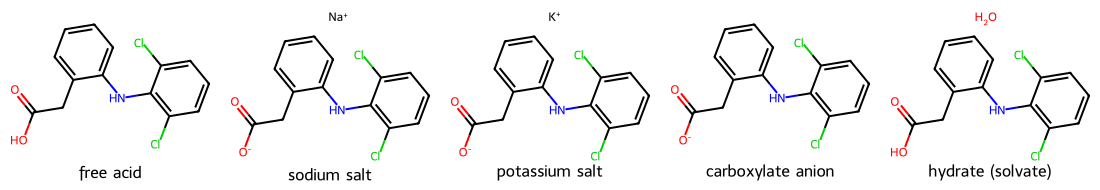

In [3]:
# Draw the five records: the eye sees "the same molecule plus junk"; the string does not.
mols = [Chem.MolFromSmiles(s) for s in records.SMILES]
Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(220, 190),
                     legends=list(records["how recorded"]))

<p class="caption"><b>Figure 1.</b> Five database records for one drug (diclofenac). To the eye the large organic fragment is identical in all five; the differences are a sodium or potassium counter-ion, a deprotonated carboxyl group, or a trapped water molecule (the small detached fragments). To a string comparison they are five different molecules — the printout above confirms the five raw strings give several distinct canonical SMILES. Standardisation exists to strip the chemically irrelevant differences so that all five collapse to a single parent structure. This is exactly the data-cleaning problem a computer scientist knows, with chemistry supplying the equivalence rule.</p>

<div class="box warn"><h4>Why this matters, concretely</h4>
<p>If you skip standardisation and feed these rows to a model: (1) your dataset over-counts diclofenac five-fold, biasing any statistic; (2) if two of the rows carry conflicting activity values (common in real exports), the model sees the "same" input with different labels and cannot learn; (3) descriptors computed on the salt include the sodium atom, so molecular weight and atom counts are wrong; (4) a similarity search for diclofenac may miss four of the five records. Every one of these failures is silent — no error is raised, the numbers are just wrong. This is why the ChEMBL database runs a published, versioned curation pipeline on every structure it stores.<sup class="c"><a href="#r1">[1]</a></sup></p></div>

## 2. Sanitisation: the gate every molecule must pass first

Before any cleaning, RDKit insists that a parsed molecule be <strong>chemically sensible</strong>. This step is called <strong>sanitisation</strong>, and it runs automatically inside <code>Chem.MolFromSmiles</code> unless you switch it off. It is not the same as standardisation: sanitisation checks that the graph <em>can exist</em>; standardisation then chooses <em>which</em> valid form to keep.

<div class="box bridge"><h4>Chemistry box — valence, kekulisation, aromaticity perception</h4>
<p><strong>Valence</strong> (Unit 1) is the number of bonds an atom normally forms: C 4, N 3, O 2, H and halogens 1. A structure that asks carbon to make five bonds is impossible, and sanitisation must reject it. <strong>Aromaticity perception</strong> is RDKit deciding which rings are aromatic (flat, electron-delocalised rings such as benzene) and flagging their atoms and bonds accordingly. <strong>Kekulisation</strong> is the inverse bookkeeping: writing an aromatic ring with explicit alternating single and double bonds, which some file formats (the widely used MDL molfile, for example)<sup class="c"><a href="#r25">[25]</a></sup> and algorithms require. All three are mechanical graph operations once the rules are fixed — but they can fail on malformed input, and that failure is the first thing a curation pipeline must catch.</p></div>

In [4]:
# Sanitisation in slow motion: parse WITHOUT sanitising, inspect, then sanitise by hand.
raw = Chem.MolFromSmiles("c1ccccc1O", sanitize=False)     # phenol, aromatic lower-case
before = [a.GetIsAromatic() for a in raw.GetAtoms()]
flags = Chem.SanitizeMol(raw)                              # returns which operations ran; raises on failure
after = [a.GetIsAromatic() for a in raw.GetAtoms()]
print("aromatic flags BEFORE sanitise:", before)
print("aromatic flags AFTER  sanitise:", after, " <- aromaticity now perceived")
print("sanitisation operations applied:", str(flags))

aromatic flags BEFORE sanitise: [True, True, True, True, True, True, False]
aromatic flags AFTER  sanitise: [True, True, True, True, True, True, False]  <- aromaticity now perceived
sanitisation operations applied: SANITIZE_NONE


Parsed with <code>sanitize=False</code> the aromatic flags are not yet set; <code>SanitizeMol</code> perceives the ring and marks its atoms aromatic, and reports the suite of checks it ran (ring finding, valence checking, kekulisation, aromaticity, and so on). When a structure is impossible, sanitisation is where the pipeline finds out — so a robust loader always catches the failure rather than letting a bad molecule through.

Under the hood <code>SanitizeMol</code> runs a fixed sequence of sub-operations, and it is worth knowing their names because an error message will mention them: it finds the smallest set of rings, checks that every atom's bonds are consistent with a possible valence, kekulises the aromatic systems (assigns a valid alternating single/double-bond pattern), perceives which rings are genuinely aromatic, sets conjugation and hybridisation flags, and computes implicit hydrogen counts. Each is a cheap graph computation, but each can reject the molecule: a ring that cannot be kekulised, an atom whose bonds exceed any allowed valence, or a charge that makes no sense. A pipeline can ask RDKit to run only a subset (for example, skip aromaticity perception) via the operation flags, but for teaching and for most curation the default full sanitisation is what you want. The single discipline to internalise is that sanitisation is a gate with a pass/fail outcome, and the number that fail is a statistic you must report, not hide.

In [5]:
# A valence error and an unparseable string both fail the gate; a good loader records why.
candidates = {"pentavalent carbon": "FC(F)(F)(F)F", "unbalanced ring": "c1ccccc",
              "ok benzene": "c1ccccc1", "ok caffeine": "Cn1cnc2c1c(=O)n(C)c(=O)n2C"}
rows = []
for name, smi in candidates.items():
    m = Chem.MolFromSmiles(smi)                 # sanitises internally; returns None on failure
    rows.append((name, smi, "PASS" if m is not None else "REJECTED"))
print(pd.DataFrame(rows, columns=["case", "SMILES", "sanitisation"]).to_string(index=False))
n_ok = sum(r[2] == "PASS" for r in rows)
print(f"\n{n_ok} of {len(rows)} structures survived the sanitisation gate")

              case                     SMILES sanitisation
pentavalent carbon               FC(F)(F)(F)F     REJECTED
   unbalanced ring                    c1ccccc     REJECTED
        ok benzene                   c1ccccc1         PASS
       ok caffeine Cn1cnc2c1c(=O)n(C)c(=O)n2C         PASS

2 of 4 structures survived the sanitisation gate


Two of the four inputs are rejected: a carbon drawn with five bonds (impossible valence) and a benzene ring that never closes (a malformed graph). <code>MolFromSmiles</code> returns <code>None</code> for both, which is RDKit's way of saying "this cannot be sanitised." The practical rule for every pipeline in this course: <strong>always check for <code>None</code> after parsing, and keep a count of what you dropped</strong> — a dataset that silently loses 3&nbsp;% of its rows to parse failures is a dataset whose results you cannot trust. The ChEMBL and PubChem pipelines both begin with exactly this validation gate before any further processing.<sup class="c"><a href="#r1">[1]</a></sup><sup class="c"><a href="#r5">[5]</a></sup>

## 3. The standardisation pipeline, one step at a time

Once a molecule is sane, standardisation decides which of its many valid spellings to keep. RDKit<sup class="c"><a href="#r14">[14]</a></sup> provides these operations in its <code>rdMolStandardize</code> module — a reimplementation of the ideas in the MolVS package and aligned with the ChEMBL curation pipeline<sup class="c"><a href="#r1">[1]</a></sup> — as composable steps; other toolchains such as the KNIME-based VSPrep workflow<sup class="c"><a href="#r19">[19]</a></sup> and Open Babel<sup class="c"><a href="#r26">[26]</a></sup> offer similar functionality. We meet them one at a time on small examples, then assemble them into a single function in Section&nbsp;6. The canonical order is: <strong>cleanup → normalise → reionise → choose parent fragment → neutralise → canonical tautomer</strong>.

### 3.1 Cleanup and normalise: fix how functional groups are drawn

<div class="box bridge"><h4>Chemistry box — a functional group drawn two ways</h4>
<p>Many functional groups (Unit 1) have more than one valid drawing. The classic case is the <strong>nitro group</strong>, −NO₂: it can be written with a pentavalent nitrogen and two double bonds, or — the form chemists prefer — with a positive nitrogen and a negative oxygen (a <em>charge-separated</em> representation). Both describe the same real group; <strong>normalisation</strong> rewrites them to one agreed form. <code>Cleanup</code> does the basic tidy-up (sanitise, remove odd features, perceive stereo); <code>Normalize</code> applies a library of such functional-group rules.</p></div>

       as written    after Normalize()
      CC[N](=O)=O       CC[N+](=O)[O-]
O=[N](=O)c1ccccc1 O=[N+]([O-])c1ccccc1
   CC[N+](=O)[O-]       CC[N+](=O)[O-]


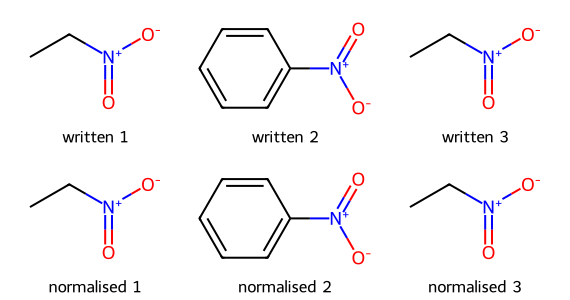

In [6]:
# Normalisation rewrites a functional group to one agreed form (nitro group shown).
norm = mstd.Normalizer()
nitro_variants = ["CC[N](=O)=O", "O=[N](=O)c1ccccc1", "CC[N+](=O)[O-]"]
before = [Chem.MolFromSmiles(s) for s in nitro_variants]
after = [norm.normalize(m) for m in before]
rows = [(s, Chem.MolToSmiles(a)) for s, a in zip(nitro_variants, after)]
print(pd.DataFrame(rows, columns=["as written", "after Normalize()"]).to_string(index=False))
Draw.MolsToGridImage(before + after, molsPerRow=3, subImgSize=(190, 150),
    legends=["written "+str(i+1) for i in range(3)] + ["normalised "+str(i+1) for i in range(3)])

<p class="caption"><b>Figure 2.</b> Three ways of writing a nitro group (top row) and the single normalised form they all map to (bottom row). The printout shows all three "after" strings are identical — <code>[N+](=O)[O-]</code>. Normalisation is a lookup table of such transformations (nitro, sulfoxide, azide, diazonium, and a few dozen more); applying it means two chemists who drew the same molecule differently now agree. This is the chemical analogue of normalising Unicode or trimming whitespace before comparing strings.</p>

### 3.2 Reionise: put the charge on the right atom

<div class="box bridge"><h4>Chemistry box — strongest-acid-first</h4>
<p>When a molecule has several acidic groups (Unit 1: an acid gives up a proton H⁺) but only some are deprotonated, which atom should carry the negative charge? Chemistry has a definite answer: the <strong>strongest acid loses its proton first</strong>. <strong>Reionisation</strong> moves protons so that the charges sit on the correct atoms regardless of how the input happened to be drawn.</p></div>

as written : O=C(O)c1ccc([O-])cc1   (phenol O-, acid OH)
reionised  : O=C([O-])c1ccc(O)cc1   (acid O-, phenol OH)


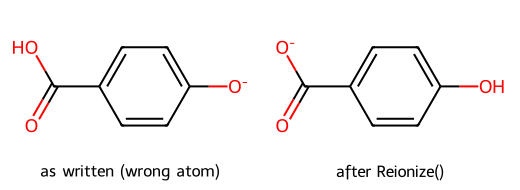

In [7]:
# A molecule drawn with the charge on the wrong atom: phenol deprotonated, acid still protonated.
reion = mstd.Reionizer()
wrong = Chem.MolFromSmiles("[O-]c1ccc(C(=O)O)cc1")   # phenolate + neutral COOH  (chemically backwards)
fixed = reion.reionize(wrong)
print("as written :", Chem.MolToSmiles(wrong), "  (phenol O-, acid OH)")
print("reionised  :", Chem.MolToSmiles(fixed), "  (acid O-, phenol OH)")
Draw.MolsToGridImage([wrong, fixed], molsPerRow=2, subImgSize=(260, 190),
                     legends=["as written (wrong atom)", "after Reionize()"])

<p class="caption"><b>Figure 3.</b> The input (left) was drawn with the negative charge on the phenol oxygen and the carboxylic acid left neutral — chemically backwards, because a carboxylic acid (pKa ≈ 4) is a far stronger acid than a phenol (pKa ≈ 10) and so loses its proton first. Reionisation (right) moves the proton to put the charge where it belongs. Without this step, two records of the same partially ionised molecule drawn by different people would never match.</p>

### 3.3 Choose the parent fragment: strip salts, solvents and counter-ions

<div class="box bridge"><h4>Chemistry box — the "parent" structure</h4>
<p>When a record contains several disconnected fragments (a dot in the SMILES), standardisation keeps the one that is the molecule of interest — the <strong>parent</strong> — and discards counter-ions, solvents and other small fragments. The usual rule is "keep the largest organic fragment". RDKit's <code>LargestFragmentChooser</code> implements this, and <code>FragmentParent</code> wraps the whole salt-stripping step.</p></div>

In [8]:
# Keep the largest fragment; discard the counter-ion / solvent.
chooser = mstd.LargestFragmentChooser()
salty = {"diclofenac sodium": "O=C([O-])Cc1ccccc1Nc1c(Cl)cccc1Cl.[Na+]",
         "amphetamine sulfate": "CC(N)Cc1ccccc1.CC(N)Cc1ccccc1.OS(=O)(=O)O",
         "caffeine hydrate": "Cn1cnc2c1c(=O)n(C)c(=O)n2C.O"}
rows = []
for name, smi in salty.items():
    m = Chem.MolFromSmiles(smi)
    nfrag = len(Chem.GetMolFrags(m))
    parent = chooser.choose(m)
    rows.append((name, nfrag, Chem.MolToSmiles(parent)))
print(pd.DataFrame(rows, columns=["record", "#fragments in", "parent kept"]).to_string(index=False))

             record  #fragments in                       parent kept
  diclofenac sodium              2 O=C([O-])Cc1ccccc1Nc1c(Cl)cccc1Cl
amphetamine sulfate              3                    CC(N)Cc1ccccc1
   caffeine hydrate              2        Cn1c(=O)c2c(ncn2C)n(C)c1=O


Each multi-fragment record is reduced to its single parent: the sodium leaves diclofenac, the sulfate and the duplicate copy leave amphetamine, the water leaves caffeine. Note the amphetamine case — the raw record held the active molecule <em>twice</em> plus a sulfate (a 2:1 salt), and the chooser still returns one clean copy. Salt and solvent stripping is usually the single most impactful standardisation step on a real database export, because salts are so common.

### 3.4 Neutralise: remove charges that are only there because of the salt

<div class="box bridge"><h4>Chemistry box — neutral parent vs physiological charge</h4>
<p>After stripping the counter-ion, the parent may still carry the charge it had in the salt (diclofenac is left as a carboxylate anion). Many pipelines <strong>neutralise</strong> the parent to a single reference state so that the salt and the free acid become identical records. RDKit's <code>Uncharger</code> does this. A subtle point we return to in Section&nbsp;9: the neutral form is a <em>bookkeeping</em> choice, not the form that exists in the body — at blood pH 7.4 (Unit 1) diclofenac is an anion. Standardise to a reference state for matching; re-apply the physiological protonation only when the model needs it.</p></div>

In [9]:
# Neutralise the parent to a single reference state so salt and free acid match.
unch = mstd.Uncharger()
cases = ["O=C([O-])Cc1ccccc1Nc1c(Cl)cccc1Cl",   # diclofenac anion (from the salt)
         "[NH3+]CCc1ccc(O)c(O)c1",               # dopamine cation (from the HCl salt)
         "O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl"]       # diclofenac already neutral
rows = []
for s in cases:
    m = Chem.MolFromSmiles(s)
    n = unch.uncharge(m)
    rows.append((Chem.MolToSmiles(m), Chem.MolToSmiles(n),
                 rdMolDescriptors.CalcMolFormula(m), rdMolDescriptors.CalcMolFormula(n)))
print(pd.DataFrame(rows, columns=["charged in", "neutralised", "formula in", "formula out"]).to_string(index=False))

                       charged in                    neutralised    formula in  formula out
O=C([O-])Cc1ccccc1Nc1c(Cl)cccc1Cl O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl C14H10Cl2NO2- C14H11Cl2NO2
           [NH3+]CCc1ccc(O)c(O)c1              NCCc1ccc(O)c(O)c1     C8H12NO2+     C8H11NO2
   O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl  C14H11Cl2NO2 C14H11Cl2NO2


The carboxylate gains back its proton (formula picks up one H and loses the negative charge); the protonated amine of dopamine loses a proton and becomes neutral. After neutralisation, the record derived from "diclofenac sodium" and the record derived from "diclofenac free acid" are finally byte-for-byte identical — which is the whole point. The third case shows the operation is idempotent: a molecule already neutral is unchanged.

## 4. Worked example by hand: strip a salt and pick the parent

Let us do the most common standardisation step — salt stripping — entirely on paper, then confirm it with code, so you can reproduce the logic without RDKit. Take the record <strong>sodium benzoate</strong>, a common food preservative, written as the SMILES <code>[Na+].[O-]C(=O)c1ccccc1</code>.

<strong>Step 1 — split on fragments.</strong> The dot separates two disconnected fragments: <code>[Na+]</code> (a sodium cation) and <code>[O-]C(=O)c1ccccc1</code> (a benzoate anion). 

<strong>Step 2 — count heavy atoms in each fragment.</strong> A "heavy atom" is any non-hydrogen atom (Unit 1). Sodium is a single atom, so 1 heavy atom. Benzoate is a benzene ring (6 carbons) plus a carboxylate (1 carbon, 2 oxygens) = 9 heavy atoms. 

<strong>Step 3 — keep the largest organic fragment.</strong> 9 &gt; 1, and the large fragment contains carbon (it is organic), so the parent is the benzoate; the sodium is discarded. 

<strong>Step 4 — neutralise.</strong> The benzoate anion carries −1. Giving the carboxylate back its proton yields neutral benzoic acid, <code>O=C(O)c1ccccc1</code>. 

The table below performs this arithmetic in code and confirms that <code>rdMolStandardize</code> reaches the same parent.

In [10]:
# Trace the four by-hand steps on sodium benzoate and confirm with rdMolStandardize.
rec = "[Na+].[O-]C(=O)c1ccccc1"
m = Chem.MolFromSmiles(rec)
frags = Chem.GetMolFrags(m, asMols=True)                       # step 1: split
tbl = [(Chem.MolToSmiles(f), f.GetNumHeavyAtoms(),             # step 2: count heavy atoms
        any(a.GetSymbol() == "C" for a in f.GetAtoms()))       #         organic?
       for f in frags]
print(pd.DataFrame(tbl, columns=["fragment", "heavy atoms", "organic?"]).to_string(index=False))
parent = mstd.Uncharger().uncharge(mstd.LargestFragmentChooser().choose(m))   # steps 3+4
by_hand = "O=C(O)c1ccccc1"                                     # what we derived on paper
print("\nby hand        :", Chem.CanonSmiles(by_hand))
print("rdMolStandardize:", Chem.MolToSmiles(parent))
print("agree          :", Chem.CanonSmiles(by_hand) == Chem.MolToSmiles(parent))

         fragment  heavy atoms  organic?
            [Na+]            1     False
O=C([O-])c1ccccc1            9      True

by hand        : O=C(O)c1ccccc1
rdMolStandardize: O=C(O)c1ccccc1
agree          : True


<p class="caption"><b>Table (Section 4).</b> The hand trace and RDKit agree: the benzoate fragment (9 heavy atoms, organic) is kept over the sodium (1 heavy atom), then neutralised to benzoic acid. The whole of salt stripping is this short algorithm — split, count, keep the largest organic fragment, neutralise — which is why you can audit it by eye on any individual record even when the pipeline runs on millions.</p>

<div class="box warn"><h4>Where "largest fragment" is the wrong rule</h4>
<p>"Keep the largest organic fragment" is a heuristic, not a law. It fails for genuine co-crystals and co-formulated drugs where both fragments matter, for organometallic complexes (the metal <em>is</em> the point), and when the counter-ion is itself a large organic molecule bigger than the active. Production pipelines keep a curated list of known salts/solvents to remove rather than blindly taking the biggest piece; RDKit's <code>FragmentRemover</code> supports exactly such a list. Always inspect what your salt stripper discarded before trusting it at scale.</p></div>

## 5. The tautomer problem

Salts and charges are visible defects. Tautomers are the insidious one, because both forms are legitimate drawings of a single substance and nothing in the string looks wrong — the practitioner literature calls this, with feeling, "the trouble with tautomers".<sup class="c"><a href="#r28">[28]</a></sup>

<div class="box bridge"><h4>Chemistry box — tautomer</h4>
<p>A <strong>tautomer</strong> is one of two or more structures of the same molecule that differ only by the position of a hydrogen atom and one double bond, and that interconvert rapidly in solution. The textbook case is <em>keto–enol</em>: a carbon–oxygen double bond with an adjacent C–H (the "keto" form) can shift to a carbon–carbon double bond with an O–H (the "enol" form). The two are the same compound — they swap back and forth billions of times a second — but they are <em>different molecular graphs</em>: different atoms bear the hydrogen, different bonds are double. For a computer scientist: the same object has several legal serialisations, and unless you pick a canonical one, your hash table stores it under several keys.<sup class="c"><a href="#r9">[9]</a></sup></p></div>

acetylacetone         5 tautomers enumerated
warfarin              9 tautomers enumerated
guanine (DNA base)   15 tautomers enumerated


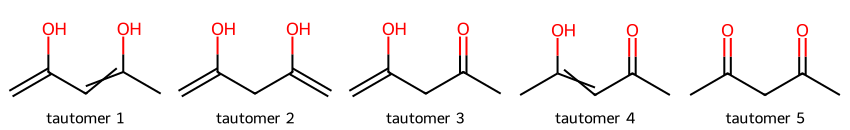

In [11]:
# Enumerate the tautomers RDKit considers plausible for three molecules.
te = mstd.TautomerEnumerator()
demo = {"acetylacetone": "CC(=O)CC(C)=O", "warfarin": "CC(=O)CC(c1ccccc1)C1=C(O)c2ccccc2OC1=O",
        "guanine (DNA base)": "Nc1nc2[nH]cnc2c(=O)[nH]1"}
counts = {}
for name, smi in demo.items():
    res = te.Enumerate(Chem.MolFromSmiles(smi))
    counts[name] = len(res)
    print(f"{name:20s} {len(res):2d} tautomers enumerated")
# draw the tautomers of the smallest example
accac = te.Enumerate(Chem.MolFromSmiles("CC(=O)CC(C)=O"))
Draw.MolsToGridImage(list(accac), molsPerRow=5, subImgSize=(170, 130),
                     legends=[f"tautomer {i+1}" for i in range(len(accac))])

<p class="caption"><b>Figure 4.</b> The tautomers RDKit enumerates for acetylacetone (shown), warfarin and guanine. Even a nine-atom molecule like acetylacetone has several; guanine, a building block of DNA, has the most of the three. Each of these is a different graph that a naive pipeline would treat as a different compound. The enumeration is combinatorial in the number of mobile hydrogens, which is why RDKit caps it — and why we need a single <em>canonical</em> tautomer, not the full list, for deduplication.</p>

### 5.1 A tautomer changes descriptors — and therefore any model

The danger is not philosophical. Pick the wrong tautomer and the numbers you compute from the structure change. The cell measures four Unit-1 descriptors on two tautomer pairs.

In [12]:
# Hydrogen-bond donors/acceptors, polar surface and logP differ between tautomers of ONE compound.
pairs = [("2-pyridone (keto)",   "O=c1cccc[nH]1"), ("2-hydroxypyridine (enol)", "Oc1ccccn1"),
         ("cyclohexanone (keto)", "O=C1CCCCC1"),   ("cyclohex-1-enol (enol)",   "OC1=CCCCC1")]
rows = []
for name, smi in pairs:
    m = Chem.MolFromSmiles(smi)
    rows.append((name, Lipinski.NumHDonors(m), Lipinski.NumHAcceptors(m),
                 round(Descriptors.TPSA(m), 1), round(Descriptors.MolLogP(m), 2)))
tauto_desc = pd.DataFrame(rows, columns=["form", "HBD", "HBA", "TPSA", "logP"])
print(tauto_desc.to_string(index=False))

                    form  HBD  HBA  TPSA  logP
       2-pyridone (keto)    1    1  32.9  0.37
2-hydroxypyridine (enol)    1    2  33.1  0.79
    cyclohexanone (keto)    0    1  17.1  1.52
  cyclohex-1-enol (enol)    1    1  20.2  2.00


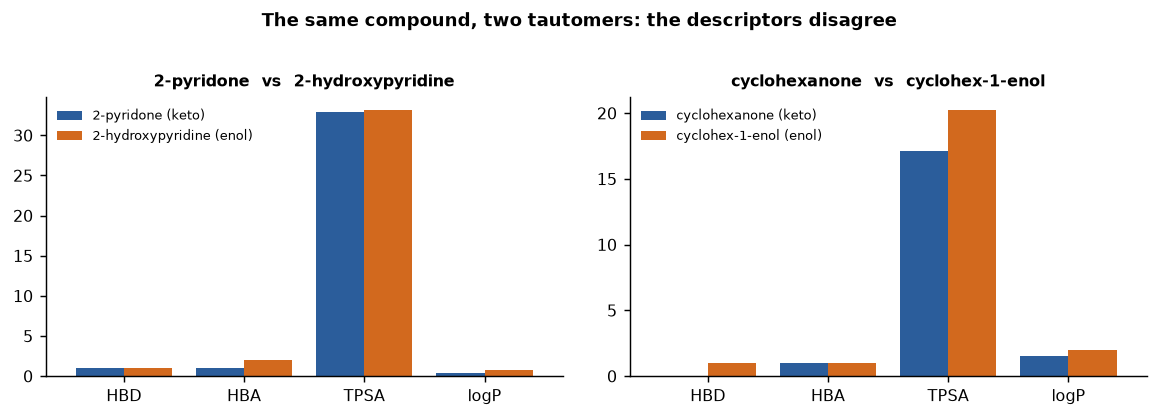

In [13]:
# Visualise the descriptor gap within each tautomer pair.
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.1))
for ax, (lo, hi, title) in zip(axes, [(0, 1, "2-pyridone  vs  2-hydroxypyridine"),
                                       (2, 3, "cyclohexanone  vs  cyclohex-1-enol")]):
    sub = tauto_desc.iloc[[lo, hi]].set_index("form")[["HBD", "HBA", "TPSA", "logP"]]
    sub.T.plot(kind="bar", ax=ax, width=0.8, color=["#2b5d9b", "#d2691e"])
    ax.set_title(title, fontsize=9); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
    ax.legend(fontsize=7, frameon=False)
fig.suptitle("The same compound, two tautomers: the descriptors disagree", y=1.02, fontsize=10, fontweight="bold")
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> Four descriptors for two tautomer pairs. Within each pair the molecule is chemically the <em>same substance</em>, yet the keto and enol forms disagree: the cyclohexanone/enol pair differs by one hydrogen-bond donor (the enol's O–H) and the 2-pyridone/2-hydroxypyridine pair differs by a hydrogen-bond acceptor and in logP. A drug-likeness filter (Unit 9) counts donors and acceptors in the spirit of Lipinski's rule of five;<sup class="c"><a href="#r24">[24]</a></sup> a QSAR model (Unit 12) consumes the Crippen logP estimate<sup class="c"><a href="#r20">[20]</a></sup> and the topological polar surface area.<sup class="c"><a href="#r21">[21]</a></sup> Feed it whichever tautomer the database happened to store and the prediction wobbles for a reason that has nothing to do with chemistry — pure representation noise.</p>

### 5.2 A tautomer changes the fingerprint even more dramatically

Descriptors shift by one or two units. Fingerprints — the circular (ECFP/Morgan) bit-vectors Unit 5 builds<sup class="c"><a href="#r22">[22]</a></sup> and the Tanimoto similarity<sup class="c"><a href="#r23">[23]</a></sup> every search consumes — can change far more, because moving a hydrogen and a double bond rewrites many local atom environments at once. The choice of fingerprint and metric is itself a benchmarked question;<sup class="c"><a href="#r27">[27]</a></sup> here the point is only that tautomer noise corrupts whichever you pick.

In [14]:
# Morgan fingerprint similarity between two tautomers, before and after canonicalisation.
a = Chem.MolFromSmiles("Cc1[nH]cnc1"); b = Chem.MolFromSmiles("Cc1nc[nH]c1")   # 4-methylimidazole tautomers
fa, fb = MORGAN.GetFingerprint(a), MORGAN.GetFingerprint(b)
sim_raw = DataStructs.TanimotoSimilarity(fa, fb)
te = mstd.TautomerEnumerator()
ca, cb = te.Canonicalize(a), te.Canonicalize(b)
fca, fcb = MORGAN.GetFingerprint(ca), MORGAN.GetFingerprint(cb)
sim_canon = DataStructs.TanimotoSimilarity(fca, fcb)
print(f"as-written tautomers : Tanimoto = {sim_raw:.2f}   (1.0 would mean identical)")
print(f"after canonical taut.: Tanimoto = {sim_canon:.2f}   same canonical SMILES? {Chem.MolToSmiles(ca)==Chem.MolToSmiles(cb)}")
print(f"bits set: A={fa.GetNumOnBits()}  B={fb.GetNumOnBits()}  shared={len(set(fa.GetOnBits())&set(fb.GetOnBits()))}")

as-written tautomers : Tanimoto = 0.28   (1.0 would mean identical)
after canonical taut.: Tanimoto = 1.00   same canonical SMILES? True
bits set: A=16  B=16  shared=7


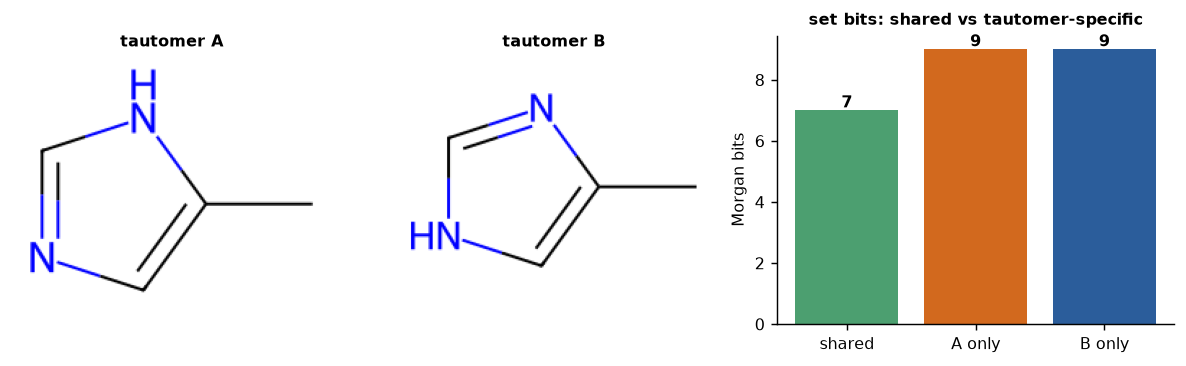

In [15]:
# Make the fingerprint gap visible: how many Morgan bits are shared vs tautomer-specific?
bits_a, bits_b = set(fa.GetOnBits()), set(fb.GetOnBits())
shared, only_a, only_b = bits_a & bits_b, bits_a - bits_b, bits_b - bits_a
fig, axes = plt.subplots(1, 3, figsize=(9.2, 2.9), gridspec_kw={"width_ratios": [1, 1, 1.25]})
axes[0].imshow(np.array(Draw.MolToImage(a, size=(220, 170)))); axes[0].axis("off"); axes[0].set_title("tautomer A", fontsize=9)
axes[1].imshow(np.array(Draw.MolToImage(b, size=(220, 170)))); axes[1].axis("off"); axes[1].set_title("tautomer B", fontsize=9)
vals = [len(shared), len(only_a), len(only_b)]
axes[2].bar(["shared", "A only", "B only"], vals, color=["#4c9f70", "#d2691e", "#2b5d9b"])
axes[2].set_ylabel("Morgan bits"); axes[2].set_title("set bits: shared vs tautomer-specific", fontsize=9)
for i, v in enumerate(vals):
    axes[2].text(i, v + 0.1, str(v), ha="center", fontsize=9, fontweight="bold")
fig.tight_layout()

<p class="caption"><b>Figure 6.</b> The two tautomers of 4-methylimidazole (left, centre) and the anatomy of their fingerprint disagreement (right). Only a minority of the set Morgan bits are shared; each tautomer carries bits the other lacks, because the mobile hydrogen and shifted double bond change the circular atom environments around half the ring. Those tautomer-specific bits are what drag the Tanimoto similarity down even though the substance is identical — a vivid picture of representation noise that canonicalisation eliminates by forcing both molecules to the same bit pattern.</p>

The two tautomers of 4-methylimidazole — a fragment of the amino acid histidine — have a raw Tanimoto similarity far below 1.0, even though they are the same substance; they share only a fraction of their set bits. A similarity search would rank one tautomer as a poor match for the other. After mapping both to the <strong>canonical tautomer</strong> the similarity becomes exactly 1.0 and the two records collapse into one. This is the single strongest argument for canonical-tautomer standardisation: it removes a representation artefact that can otherwise masquerade as real chemical dissimilarity.<sup class="c"><a href="#r7">[7]</a></sup><sup class="c"><a href="#r10">[10]</a></sup>

<div class="box warn"><h4>Canonical ≠ "biologically correct"</h4>
<p>RDKit's canonical tautomer is chosen by a scoring function to be <em>consistent</em>, not necessarily the tautomer that dominates in water or the one that binds the protein. Those are different, harder questions (the dominant tautomer depends on environment and pH). For deduplication and modelling you want consistency, and canonicalisation delivers it; just do not read biological meaning into which tautomer was chosen.<sup class="c"><a href="#r8">[8]</a></sup></p></div>

## 6. Build one standardisation function

We now assemble the individual steps into a single function — the artefact you will actually reuse in later units — in the order the ChEMBL pipeline uses:<sup class="c"><a href="#r1">[1]</a></sup> cleanup, normalise, reionise, choose the parent fragment, neutralise, and finally canonicalise the tautomer. The function returns the canonical SMILES string, which is the key we deduplicate on.

In [16]:
_TE = mstd.TautomerEnumerator()                 # build once; reusing it is much faster than per-call
_LFC = mstd.LargestFragmentChooser()
_UNCHARGE = mstd.Uncharger()
_NORM = mstd.Normalizer()

def standardize(smiles):
    '''Return the canonical SMILES of the standardised parent, or None if the input cannot be parsed.'''
    m = Chem.MolFromSmiles(smiles)              # sanitisation gate (Section 2)
    if m is None:
        return None
    m = mstd.Cleanup(m)                         # basic tidy-up
    m = _NORM.normalize(m)                      # functional-group normalisation (Section 3.1)
    m = mstd.Reionize(m)                        # charge on the right atom (Section 3.2)
    m = _LFC.choose(m)                          # keep the parent fragment (Section 3.3)
    m = _UNCHARGE.uncharge(m)                   # neutralise to reference state (Section 3.4)
    m = _TE.Canonicalize(m)                     # canonical tautomer (Section 5)
    return Chem.MolToSmiles(m)

print("sodium benzoate ->", standardize("[Na+].[O-]C(=O)c1ccccc1"))
print("2-hydroxypyridine ->", standardize("Oc1ccccn1"))
print("unparseable 'xyz' ->", standardize("xyz"))

sodium benzoate -> O=C(O)c1ccccc1
2-hydroxypyridine -> O=c1cccc[nH]1
unparseable 'xyz' -> None


In [17]:
# Run the function on the five diclofenac records from Section 1: they must all collapse to one.
records["standardised"] = [standardize(s) for s in records.SMILES]
print(records[["id", "how recorded", "standardised"]].to_string(index=False))
print("\ndistinct raw canonical SMILES :", records.raw_canonical.nunique())
print("distinct AFTER standardisation:", records.standardised.nunique(), " <- the five records are now one compound")

   id      how recorded                   standardised
rec-1         free acid O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl
rec-2       sodium salt O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl
rec-3    potassium salt O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl
rec-4 carboxylate anion O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl
rec-5 hydrate (solvate) O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl

distinct raw canonical SMILES : 5
distinct AFTER standardisation: 1  <- the five records are now one compound


<p class="caption"><b>Table (Section 6).</b> The five diclofenac records from Figure 1 — free acid, sodium salt, potassium salt, bare anion, hydrate — now share one identical standardised SMILES, so the count of distinct compounds drops from several to one. The same six-line function will run unchanged on a thousand structures in the next section. Notice it returns <code>None</code> for unparseable input, so the caller can count and quarantine failures rather than crash.</p>

## 7. Apply it to a thousand raw structures and count the collapse

The pay-off of standardisation is measurable: on a real export, many "different" records turn out to be the same compound. We build a thousand-record messy dataset the way a database accumulates one — a modest pool of real drugs, each deposited many times under different (non-canonical) SMILES spellings and with assorted salts, solvents and counter-ions — then measure deduplication at three levels of sophistication. The dataset is generated deterministically (fixed random seed) so the numbers below are reproducible.

In [18]:
# Build 1,000 raw records from a pool of 20 real drugs, each polluted with random salts/solvents/charges.
POOL = {
 "aspirin":"CC(=O)Oc1ccccc1C(=O)O", "ibuprofen":"CC(C)Cc1ccc(C(C)C(=O)O)cc1",
 "paracetamol":"CC(=O)Nc1ccc(O)cc1", "caffeine":"Cn1cnc2c1c(=O)n(C)c(=O)n2C",
 "dopamine":"NCCc1ccc(O)c(O)c1", "salbutamol":"CC(C)(C)NCC(O)c1ccc(O)c(CO)c1",
 "atenolol":"CC(C)NCC(O)COc1ccc(CC(N)=O)cc1", "diphenhydramine":"CN(C)CCOC(c1ccccc1)c1ccccc1",
 "naproxen":"COc1ccc2cc(C(C)C(=O)O)ccc2c1", "metformin":"CN(C)C(=N)NC(N)=N",
 "warfarin":"CC(=O)CC(c1ccccc1)C1=C(O)c2ccccc2OC1=O", "fluoxetine":"CNCCC(Oc1ccc(C(F)(F)F)cc1)c1ccccc1",
 "lidocaine":"CCN(CC)CC(=O)Nc1c(C)cccc1C", "nicotine":"CN1CCCC1c1cccnc1",
 "serotonin":"NCCc1c[nH]c2ccc(O)cc12", "ketoprofen":"CC(C(=O)O)c1cccc(C(=O)c2ccccc2)c1",
 "procaine":"CCN(CC)CCOC(=O)c1ccc(N)cc1", "amphetamine":"CC(N)Cc1ccccc1",
 "theophylline":"Cn1c(=O)c2[nH]cnc2n(C)c1=O", "gabapentin":"NCC1(CC(=O)O)CCCCC1"}
SALTS = ["[Cl-]", "[Na+]", "[Na+].[Cl-]", "O", "OS(=O)(=O)O", "CC(=O)O", "Cl", "[K+]"]
names = list(POOL)
base = {n: Chem.MolFromSmiles(s) for n, s in POOL.items()}
rng = random.Random(0)
raw = []
for i in range(1000):
    m = base[names[i % len(names)]]
    if rng.random() < 0.45:                        # ~45% deposited with a NON-canonical spelling
        s = Chem.MolToSmiles(m, rootedAtAtom=rng.randrange(m.GetNumAtoms()), canonical=False)
    else:                                           # the rest as the pool's own SMILES
        s = Chem.MolToSmiles(m)
    r = rng.random()
    if r < 0.45:
        s = s + "." + rng.choice(SALTS)            # attach a salt/solvent fragment
    elif r < 0.60:
        s = s + ".[Cl-]"                            # a hydrochloride-style record
    raw.append(s)
print("built", len(raw), "raw records from", len(POOL), "real compounds")

built 1000 raw records from 20 real compounds


In [19]:
# Three levels of deduplication, from naive to chemically correct.
lvl1 = len(set(raw))                                              # exact string match
lvl2 = len({Chem.MolToSmiles(Chem.MolFromSmiles(s)) for s in raw})  # canonical SMILES, no standardisation
t0 = time.time()
std = [standardize(s) for s in raw]
elapsed = time.time() - t0
lvl3 = len(set(std))                                             # after full standardisation
dedup = pd.DataFrame({"method": ["raw string match", "canonical SMILES only", "full standardisation"],
                      "distinct compounds": [lvl1, lvl2, lvl3]})
print(dedup.to_string(index=False))
print(f"\ntrue number of compounds in the pool: {len(POOL)}")
print(f"standardised 1,000 structures in {elapsed:.1f} s")

               method  distinct compounds
     raw string match                 481
canonical SMILES only                 175
 full standardisation                  20

true number of compounds in the pool: 20
standardised 1,000 structures in 1.2 s


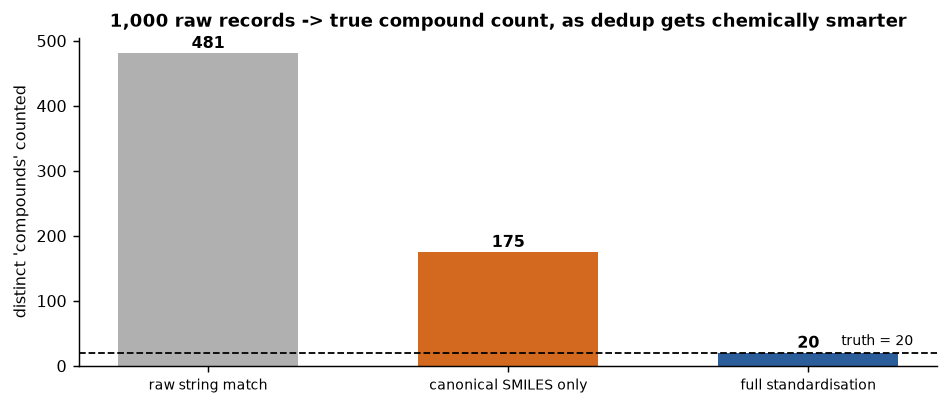

In [20]:
# Visualise the collapse: each layer of chemical awareness removes more spurious "compounds".
fig, ax = plt.subplots(figsize=(7.4, 3.2))
colors = ["#b0b0b0", "#d2691e", "#2b5d9b"]
bars = ax.bar(dedup["method"], dedup["distinct compounds"], color=colors, width=0.6)
ax.axhline(len(POOL), color="k", ls="--", lw=1)
ax.text(2.35, len(POOL) + 12, f"truth = {len(POOL)}", fontsize=8, ha="right")
ax.set_ylabel("distinct 'compounds' counted")
ax.set_title("1,000 raw records -> true compound count, as dedup gets chemically smarter")
for b, v in zip(bars, dedup["distinct compounds"]):
    ax.text(b.get_x() + b.get_width()/2, v + 8, str(v), ha="center", fontsize=9, fontweight="bold")
ax.tick_params(axis="x", rotation=0, labelsize=8)
fig.tight_layout()

<p class="caption"><b>Figure 7.</b> The same thousand records counted three ways. Exact string matching sees hundreds of "distinct" compounds (the grey bar) because the same molecule is deposited under many non-canonical spellings and with many different salts. Canonicalising each structure (orange) helps substantially — it collapses all the alternative spellings of one molecule to a single string — but still counts every salt, solvate and tautomer as separate, so it lands well short of the truth. Only full standardisation (blue) reaches the true count of 20 compounds (dashed line). The gap between the grey and blue bars is the number of duplicate rows a naive pipeline would have silently kept, with all the over-counting and label-conflict damage described in Section 1.</p>

<div class="box bridge"><h4>Bridge — this is why deduplication keys matter</h4>
<p>A computer scientist deduplicates by hashing a canonical key. The whole of this unit is the argument that the <em>right</em> key for a molecule is its standardised canonical SMILES<sup class="c"><a href="#r12">[12]</a></sup> (or the derived InChIKey — the fixed-length hash of the IUPAC InChI identifier,<sup class="c"><a href="#r13">[13]</a></sup> Unit 6), not the raw string. Get the key right once, here, and every count, join and train/test split downstream is correct; get it wrong and no amount of model tuning repairs the leakage and over-counting.</p></div>

### 7.1 The same thing on a live database export

The pool above was synthetic so the numbers are reproducible. The cell below does the real thing: it fetches a handful of molecules from the ChEMBL REST API (European Bioinformatics Institute)<sup class="c"><a href="#r2">[2]</a></sup><sup class="c"><a href="#r3">[3]</a></sup> and standardises them. In Colab or any networked machine the fetch succeeds; if the network is slow or blocked, the cell falls back to a small hard-coded sample of genuine ChEMBL records so the notebook always runs. Either way the point is the same — real database SMILES arrive as salts and in database-specific spellings that standardisation reconciles.

In [21]:
# Fetch a few real ChEMBL molecules; fall back to a bundled sample if the network is unavailable.
CHEMBL_IDS = ["CHEMBL25", "CHEMBL112", "CHEMBL113", "CHEMBL192", "CHEMBL605"]  # aspirin, paracetamol, caffeine, sildenafil, procainamide HCl
FALLBACK = {"CHEMBL25":"CC(=O)Oc1ccccc1C(=O)O", "CHEMBL112":"CC(=O)Nc1ccc(O)cc1",
            "CHEMBL113":"Cn1c(=O)c2c(ncn2C)n(C)c1=O",                      # caffeine, ChEMBL's spelling
            "CHEMBL192":"CCCc1nn(C)c2c1nc(-c1cc(S(=O)(=O)N3CCN(C)CC3)ccc1OCC)[nH]c2=O",
            "CHEMBL605":"CCN(CC)CCNC(=O)c1ccc(N)cc1.Cl"}                   # procainamide, deposited as the hydrochloride salt
source = "live ChEMBL API"
try:
    url = ("https://www.ebi.ac.uk/chembl/api/data/molecule?molecule_chembl_id__in="
           + ",".join(CHEMBL_IDS) + "&format=json")
    with urllib.request.urlopen(url, timeout=8) as resp:
        mols_json = json.load(resp)["molecules"]
    fetched = {m["molecule_chembl_id"]: (m.get("molecule_structures") or {}).get("canonical_smiles")
               for m in mols_json}
    fetched = {k: v for k, v in fetched.items() if v}
except Exception as e:
    fetched = FALLBACK; source = f"bundled fallback ({type(e).__name__})"
print("data source:", source, "|", len(fetched), "records")

data source: live ChEMBL API | 5 records


In [22]:
# Standardise the fetched records and show the database SMILES next to the standardised parent.
rows = []
for cid, smi in fetched.items():
    rows.append((cid, smi[:46] + ("..." if len(smi) > 46 else ""), standardize(smi)))
chembl_df = pd.DataFrame(rows, columns=["ChEMBL ID", "database SMILES (truncated)", "standardised parent"])
print(chembl_df.to_string(index=False))
has_dot = sum("." in s for s in fetched.values())
print(f"\n{has_dot} of {len(fetched)} database records contained a dot (a salt/mixture) before standardisation")

ChEMBL ID                       database SMILES (truncated)                                            standardised parent
 CHEMBL25                             CC(=O)Oc1ccccc1C(=O)O                                          CC(=O)Oc1ccccc1C(=O)O
CHEMBL112                                CC(=O)Nc1ccc(O)cc1                                             CC(=O)Nc1ccc(O)cc1
CHEMBL113                        Cn1c(=O)c2c(ncn2C)n(C)c1=O                                     Cn1c(=O)c2c(ncn2C)n(C)c1=O
CHEMBL605                     CCN(CC)CCNC(=O)c1ccc(N)cc1.Cl                                     CCN(CC)CCNC(=O)c1ccc(N)cc1
CHEMBL192 CCCc1nn(C)c2c(=O)[nH]c(-c3cc(S(=O)(=O)N4CCN(C)... CCCc1nn(C)c2c(=O)[nH]c(-c3cc(S(=O)(=O)N4CCN(C)CC4)ccc3OCC)nc12

1 of 5 database records contained a dot (a salt/mixture) before standardisation


<p class="caption"><b>Table (Section 7.1).</b> Real ChEMBL records and their standardised parents. Two observations a computer scientist should take from this: (1) at least one record (procainamide) arrives as a hydrochloride salt — a dot in the SMILES — that our pipeline strips to the parent, exactly as on the synthetic data; (2) the clean records come back <em>unchanged</em>, which is not luck — ChEMBL curates its own structures with the very RDKit pipeline this unit uses,<sup class="c"><a href="#r1">[1]</a></sup> so its canonical SMILES already agree with ours. That agreement is a consequence of a <em>shared</em> convention, not a property of databases in general: PubChem uses a different standardisation,<sup class="c"><a href="#r5">[5]</a></sup> so the same molecule can arrive spelled differently from there. The lesson is unchanged — re-standardise every source through your own documented, versioned pipeline rather than assuming two databases agree.<sup class="c"><a href="#r4">[4]</a></sup><sup class="c"><a href="#r6">[6]</a></sup>

## 8. Stereochemistry in practice

The title of this unit includes stereochemistry because it is the one structural feature standardisation must handle with care: unlike a salt or a tautomer, stereochemistry is usually <em>real information you must not throw away</em> — except when you must.

<div class="box bridge"><h4>Chemistry box — chirality, enantiomers, stereocentre</h4>
<p>Two molecules can have the identical graph — same atoms, same bonds — yet be non-superimposable mirror images, like your left and right hands. Such molecules are <strong>enantiomers</strong>, and the property is <strong>chirality</strong> (from the Greek for "hand"). The usual cause is a carbon with four different groups attached, called a <strong>stereocentre</strong>; swapping two groups gives the mirror image. Chirality matters enormously in biology: one enantiomer of a drug can be the medicine and the other inactive or toxic (the thalidomide tragedy is the infamous example). In SMILES, chirality is written with <code>@</code> and <code>@@</code> markers, and double-bond geometry (<em>cis/trans</em>, or <em>E/Z</em>) with <code>/</code> and <code>\</code>.</p></div>

In [23]:
# Two enantiomers of ibuprofen: same graph, mirror-image configuration.
enantA = "C[C@H](C(=O)O)c1ccc(CC(C)C)cc1"
enantB = "C[C@@H](C(=O)O)c1ccc(CC(C)C)cc1"
mA, mB = Chem.MolFromSmiles(enantA), Chem.MolFromSmiles(enantB)
print("canonical with stereo:")
print("  A:", Chem.MolToSmiles(mA))
print("  B:", Chem.MolToSmiles(mB))
print("  identical with stereo kept? ", Chem.MolToSmiles(mA) == Chem.MolToSmiles(mB))
print("canonical WITHOUT stereo (isomericSmiles=False):")
print("  identical? ", Chem.MolToSmiles(mA, isomericSmiles=False) == Chem.MolToSmiles(mB, isomericSmiles=False))
from rdkit.Chem import FindMolChiralCenters
print("stereocentres in A:", FindMolChiralCenters(mA, useLegacyImplementation=False))

canonical with stereo:
  A: CC(C)Cc1ccc([C@H](C)C(=O)O)cc1
  B: CC(C)Cc1ccc([C@@H](C)C(=O)O)cc1
  identical with stereo kept?  False
canonical WITHOUT stereo (isomericSmiles=False):
  identical?  True
stereocentres in A: [(1, 'S')]


With stereochemistry retained, the two enantiomers have <em>different</em> canonical SMILES (one <code>@</code>, one <code>@@</code>) and so are correctly counted as two compounds; drop the stereo markers and they collapse to one. RDKit reports a single stereocentre with its CIP label (the formal R/S descriptor). This is the crux of the standardisation decision: <strong>whether to keep or strip stereochemistry is a modelling choice, and standardisation must be consistent about it.</strong>

StereoParent of A (stereo removed): CC(C)Cc1ccc(C(C)C(=O)O)cc1


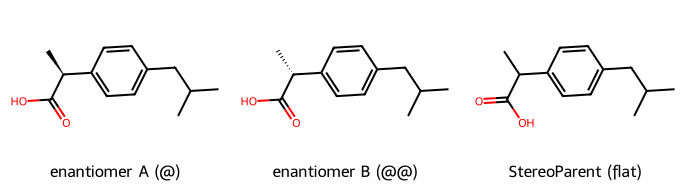

In [24]:
# Keep stereo (default) vs strip it with StereoParent; draw both enantiomers.
flat = mstd.StereoParent(Chem.MolFromSmiles(enantA))
print("StereoParent of A (stereo removed):", Chem.MolToSmiles(flat))
img = Draw.MolsToGridImage([mA, mB, flat], molsPerRow=3, subImgSize=(230, 190),
      legends=["enantiomer A (@)", "enantiomer B (@@)", "StereoParent (flat)"])
img

<p class="caption"><b>Figure 8.</b> Two enantiomers of ibuprofen and their shared flat <code>StereoParent</code>. The wedge/hash bonds at the stereocentre (the drawing convention for "coming towards you" / "going away") point in opposite directions in A and B — the only difference between them. For a model that predicts a property insensitive to 3D shape, stripping stereo is reasonable and reduces sparsity; for a model of binding to a chiral protein pocket, discarding it destroys the signal. The default ChEMBL pipeline <em>preserves</em> stereochemistry;<sup class="c"><a href="#r1">[1]</a></sup> strip it only deliberately, and record that you did.</p>

<div class="box warn"><h4>Undefined vs defined stereochemistry</h4>
<p>A third case bites in practice: a stereocentre that is <em>present but unspecified</em> in the record (the database did not know, or did not store, the configuration). Such a molecule is neither clearly one enantiomer nor flat — it is ambiguous. A curation pipeline should detect unspecified stereocentres (RDKit's <code>FindPotentialStereo</code> does) and decide a policy: keep as-is, flag for review, or expand to the possible configurations. Treating "unspecified" as "no stereocentre" is a common and damaging bug.</p></div>

Chirality is not the only kind of stereochemistry a pipeline must respect. A carbon–carbon double bond cannot rotate, so the groups on either side are locked into a fixed geometry — <em>cis</em> (same side, labelled <em>Z</em>) or <em>trans</em> (opposite sides, <em>E</em>). Like enantiomers, the two geometric isomers share an identical flat graph but are genuinely different substances with different properties. The textbook pair is maleic acid (<em>Z</em>) and fumaric acid (<em>E</em>): same formula, same connectivity, yet one is a mild irritant and the other a metabolite present in every living cell. The cell confirms that standardisation keeps the geometry (encoded in SMILES by the <code>/</code> and <code>\\</code> bond symbols) and only collapses the two when geometry is deliberately discarded.

same flat graph (geometry stripped)? True
different when geometry kept?         True
standardised Z: O=C(O)/C=C\C(=O)O
standardised E: O=C(O)/C=C/C(=O)O


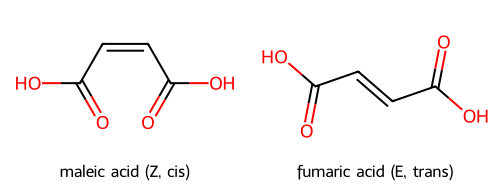

In [25]:
# Double-bond geometry (E/Z) is real chemistry: maleic (Z) and fumaric (E) acid are different compounds.
Z = Chem.MolFromSmiles("OC(=O)/C=C\\C(=O)O")      # maleic acid  (cis,  Z)
E = Chem.MolFromSmiles("OC(=O)/C=C/C(=O)O")       # fumaric acid (trans, E)
print("same flat graph (geometry stripped)?", Chem.MolToSmiles(Z, isomericSmiles=False) == Chem.MolToSmiles(E, isomericSmiles=False))
print("different when geometry kept?        ", Chem.MolToSmiles(Z) != Chem.MolToSmiles(E))
print("standardised Z:", standardize("OC(=O)/C=C\\C(=O)O"))
print("standardised E:", standardize("OC(=O)/C=C/C(=O)O"))
Draw.MolsToGridImage([Z, E], molsPerRow=2, subImgSize=(250, 190),
                     legends=["maleic acid (Z, cis)", "fumaric acid (E, trans)"])

<p class="caption"><b>Figure 9.</b> Maleic acid (<em>Z</em>) and fumaric acid (<em>E</em>): identical when geometry is stripped (first printout <code>True</code>) but distinct when it is kept (second printout <code>True</code>), and standardisation preserves the distinction — the two standardised SMILES differ. The lesson mirrors Section 8's chirality case: double-bond geometry is information, not noise, so a standardisation pipeline must carry it through unless the modelling task has an explicit reason to drop it.</p>

## 9. Standardisation is a chemical judgement, not a fixed recipe

It is tempting to treat the six-line function of Section 6 as <em>the</em> correct standardisation. It is not — it is <em>a</em> defensible policy, and a different task may justify a different one. Three honest caveats close the unit.

1. <strong>There is no universal canonical form.</strong> ChEMBL, PubChem and a given lab pipeline each make slightly different choices (which salts to strip, whether to neutralise, which tautomer scores highest, whether to keep stereo), so the "same" molecule can have different standardised SMILES in different systems.<sup class="c"><a href="#r1">[1]</a></sup><sup class="c"><a href="#r5">[5]</a></sup> Reproducibility therefore requires recording <em>which</em> pipeline and <em>which version</em> produced a given key — the RDKit version string printed in the setup cell is part of your data provenance, not decoration.
2. <strong>Neutralising is for matching, not for modelling physiology.</strong> We neutralised to a reference state so salts and free acids collapse. But at blood pH 7.4 (Unit 1) most acids are anions and most amines are cations, and that charged form is what binds the target and what a physics-based descriptor should see. The correct workflow is: standardise to a neutral reference for deduplication, then, if the model needs it, apply a separate protonation step at the chosen pH. Conflating the two is a frequent error.
3. <strong>Curation is where most "model failures" actually originate.</strong> A substantial literature shows that errors in public chemical databases are common and that careless curation, not weak algorithms, is the dominant source of unreliable QSAR models.<sup class="c"><a href="#r15">[15]</a></sup><sup class="c"><a href="#r16">[16]</a></sup><sup class="c"><a href="#r17">[17]</a></sup><sup class="c"><a href="#r18">[18]</a></sup> The "trust but verify" guidance and the quality alerts cited here predate most of the deep-learning era and have only grown more relevant as datasets grow.

<div class="box key"><h4>The one habit to keep</h4>
<p>Standardise every structure through one documented, versioned pipeline before you compute a single descriptor, build a single fingerprint, or make a single train/test split — and store the standardised canonical SMILES (or InChIKey) as the key you deduplicate and join on. Everything in Units 5–18 assumes this has been done. The tools (<code>rdMolStandardize</code>) are a few lines; the discipline is the hard part.</p></div>

## 10. Summary

You should now be able to explain, without notes:

- Why a compound collection must be standardised before any analysis, and the concrete defects — salts, counter-ions, solvates, mixtures, charge states, tautomers — that make two records of the same real molecule look different to a program.
- What RDKit sanitisation checks (valence, ring perception, kekulisation, aromaticity) and why a robust loader must test for <code>None</code> and count parse failures rather than let bad structures through.
- The standardisation pipeline step by step — cleanup, normalise (functional-group forms), reionise (charge on the strongest acid), choose the parent fragment (strip salts/solvents), neutralise, canonical tautomer — and the chemical justification for each.
- The salt-stripping algorithm traced by hand: split on fragments, count heavy atoms, keep the largest organic fragment, neutralise — and why "largest fragment" is a heuristic with known failure cases.
- The tautomer problem: that a tautomer choice changes descriptors (HBD/HBA/TPSA/logP) by one or two units and fingerprint similarity far more, so that canonicalising the tautomer is essential for consistent deduplication and modelling.
- How to write one reusable <code>standardize()</code> function and apply it to a thousand structures, and how to measure duplicate collapse at three levels (raw string, canonical SMILES, full standardisation).
- How stereochemistry is preserved by default and stripped deliberately with <code>StereoParent</code>, and why undefined stereocentres need an explicit policy.
- Why standardisation is a documented, versioned chemical judgement — not a universal canonical form — and why curation, not algorithms, is where most model failures originate.<sup class="c"><a href="#r15">[15]</a></sup>

## 11. Self-assessment

<details><summary>1. Two database rows hold the SMILES <code>O=C(O)c1ccccc1</code> and <code>O=C([O-])c1ccccc1.[Na+]</code>. Are they the same compound, and will a string comparison say so?</summary>Chemically they are the same active molecule — benzoic acid and its sodium salt. A string comparison (and even plain canonicalisation) says they are different, because one carries a sodium counter-ion and a deprotonated carboxylate. Only after salt stripping and neutralisation do they become the identical standardised SMILES.</details>

<details><summary>2. What is the difference between sanitisation and standardisation?</summary>Sanitisation checks that a molecular graph <em>can exist</em> — correct valences, perceivable aromaticity, a kekulisable ring system — and fails (returns <code>None</code>) if not. Standardisation then chooses <em>which</em> of the many valid spellings of a sane molecule to keep (which fragment, which charges, which tautomer). Sanitisation is the gate; standardisation is the normalisation that follows it.</details>

<details><summary>3. <code>Chem.MolFromSmiles</code> returned <code>None</code> for 4 % of your records. What should the pipeline do, and what must it never do?</summary>It should count and log the 4 %, quarantine those records for inspection, and report the drop rate as part of the dataset's provenance. It must never silently discard them, because a systematic parse failure (e.g. all organometallics) can bias the surviving dataset in ways that corrupt every downstream result.</details>

<details><summary>4. In the order cleanup → normalise → reionise → choose parent → neutralise → canonical tautomer, why does salt stripping come before neutralisation?</summary>The salt is stripped first so that only the parent fragment remains; neutralisation then acts on the parent alone, giving it back (or removing) protons to reach a single reference charge state. Neutralising before stripping could move charges onto a counter-ion that is about to be discarded, wasting work and risking inconsistent intermediate states.</details>

<details><summary>5. Trace by hand: what parent does standardisation return for potassium acetate, <code>CC(=O)[O-].[K+]</code>?</summary>Split on the dot: fragments are acetate (<code>CC(=O)[O-]</code>, 4 heavy atoms, organic) and potassium (1 heavy atom). Keep the larger organic fragment (acetate), then neutralise to acetic acid <code>CC(=O)O</code>. The potassium is discarded.</details>

<details><summary>6. Define "tautomer" for a programmer, and say why tautomers are more dangerous than salts.</summary>A tautomer is one of several graphs of the same molecule differing only by the position of a mobile hydrogen and a double bond; they interconvert in solution. For a programmer: the same object has several legal serialisations. They are more dangerous than salts because nothing in the string looks wrong — there is no dot, no obvious counter-ion — so the duplication is invisible unless you canonicalise the tautomer.</details>

<details><summary>7. Two tautomers of one compound gave Morgan-fingerprint Tanimoto far below 1.0. Does that mean they are chemically dissimilar?</summary>No. They are the same substance; the low similarity is a pure representation artefact caused by moving a hydrogen and a double bond, which rewrites many circular atom environments. Mapping both to the canonical tautomer restores a Tanimoto of 1.0. This is exactly why canonical-tautomer standardisation is needed before any similarity calculation.</details>

<details><summary>8. A keto tautomer has 0 hydrogen-bond donors and its enol form has 1. Which Unit-9 and Unit-12 tasks does this affect?</summary>The donor count feeds drug-likeness rules (Lipinski's rule of five, Unit 9) and both forms feed descriptor-based QSAR models (Unit 12) via logP and TPSA, which also differ between the forms. Using an inconsistent tautomer injects noise into filters and predictions that has nothing to do with real chemistry.</details>

<details><summary>9. You standardised 1,000 records and got 20 distinct compounds, but exact string matching found several hundred. What does the gap represent?</summary>The gap is the number of duplicate records a naive pipeline would have kept — the same 20 compounds deposited many times under different SMILES spellings and as different salts, solvates and charge states. Canonicalising the string removes the spelling duplicates but not the salts; only full standardisation removes both. Keeping the duplicates over-counts compounds, can create conflicting labels for the "same" input, and leaks duplicates across a train/test split.</details>

<details><summary>10. Your <code>standardize()</code> neutralised every molecule. Is the neutral form the one that exists in the body?</summary>No. Neutralisation gives a single reference state for matching/deduplication. At blood pH 7.4 most acids are anions and most amines are cations (Unit 1, Henderson–Hasselbalch). If a model needs the physiological form, apply a separate protonation step at the chosen pH after standardising; do not confuse the two.</details>

<details><summary>11. Two enantiomers have identical 2D graphs. When is it correct to strip their stereochemistry during standardisation, and when is it a serious error?</summary>Stripping stereo (e.g. with <code>StereoParent</code>) is reasonable when the modelled property is insensitive to 3D configuration, reducing sparsity. It is a serious error when modelling binding to a chiral target, where the two enantiomers can have very different activity — discarding the stereo markers destroys the signal. The choice must be deliberate and recorded.</details>

<details><summary>12. Why is "run RDKit's default standardisation" not a complete description of a reproducible pipeline?</summary>Because standardisation choices differ between toolkits and versions (which salts, whether to neutralise, which tautomer scores highest, whether to keep stereo), the "same" molecule can get different keys in different systems. Reproducibility requires recording the exact pipeline <em>and</em> its version (the RDKit version string is provenance), so another worker can regenerate identical keys.</details>

## Glossary

<dl class="gloss">
<dt>Sanitisation</dt><dd>RDKit's check that a parsed molecule is chemically valid — correct valences, perceived aromaticity, a kekulisable ring system; returns <code>None</code> on failure.</dd>
<dt>Standardisation</dt><dd>Choosing a single canonical representation for a sane molecule: normalise functional groups, fix charges, strip salts/solvents, neutralise, canonicalise the tautomer.</dd>
<dt>Salt / counter-ion</dt><dd>A compound of a charged molecule and a small ion of opposite charge; the counter-ion (Na⁺, Cl⁻, …) is removed during salt stripping.</dd>
<dt>Solvate / hydrate</dt><dd>A crystal that traps solvent molecules; a hydrate traps water. Represented as an extra disconnected fragment and removed by parent selection.</dd>
<dt>Parent fragment</dt><dd>The molecule of interest kept when a record has several disconnected fragments — usually the largest organic one.</dd>
<dt>Normalisation</dt><dd>Rewriting a functional group drawn several valid ways (e.g. a nitro group) to one agreed form.</dd>
<dt>Reionisation</dt><dd>Moving protons so that, when several acidic groups are present, the charge sits on the strongest acid.</dd>
<dt>Neutralisation (uncharging)</dt><dd>Removing charges from the parent to reach a single reference state for matching; distinct from physiological protonation.</dd>
<dt>Tautomer</dt><dd>One of several structures of the same molecule differing only by the position of a mobile hydrogen and a double bond; they interconvert rapidly.</dd>
<dt>Canonical tautomer</dt><dd>A single tautomer chosen by a scoring function so that all tautomers of one compound map to the same representation (consistent, not necessarily biologically dominant).</dd>
<dt>Chirality / enantiomer</dt><dd>A molecule non-superimposable on its mirror image is chiral; the two mirror images are enantiomers, differing at a stereocentre.</dd>
<dt>Stereocentre</dt><dd>Usually a carbon bearing four different groups; swapping two gives the enantiomer. Written in SMILES with <code>@</code>/<code>@@</code>.</dd>
<dt>Canonical SMILES</dt><dd>The unique SMILES a toolkit assigns to a molecule, used as a deduplication key after standardisation.</dd>
<dt>InChI / InChIKey</dt><dd>The IUPAC standard identifier for a molecule and its fixed-length hash; an alternative standardised key.</dd>
<dt>Heavy atom</dt><dd>Any non-hydrogen atom; the quantity compared when selecting the largest fragment.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Bento AP, Hersey A, Félix E, et al. An open source chemical structure curation pipeline using RDKit. <em>J Cheminform</em>. 2020;12:51. <a href="https://doi.org/10.1186/s13321-020-00456-1">doi:10.1186/s13321-020-00456-1</a></li>
<li id="r2">Gaulton A, Bellis LJ, Bento AP, et al. ChEMBL: a large-scale bioactivity database for drug discovery. <em>Nucleic Acids Res</em>. 2012;40(D1):D1100–D1107. <a href="https://doi.org/10.1093/nar/gkr777">doi:10.1093/nar/gkr777</a></li>
<li id="r3">Mendez D, Gaulton A, Bento AP, et al. ChEMBL: towards direct deposition of bioassay data. <em>Nucleic Acids Res</em>. 2019;47(D1):D930–D940. <a href="https://doi.org/10.1093/nar/gky1075">doi:10.1093/nar/gky1075</a></li>
<li id="r4">Zdrazil B, Felix E, Hunter F, et al. The ChEMBL Database in 2023: a drug discovery platform spanning multiple bioactivity data types and time periods. <em>Nucleic Acids Res</em>. 2024;52(D1):D1180–D1192. <a href="https://doi.org/10.1093/nar/gkad1004">doi:10.1093/nar/gkad1004</a></li>
<li id="r5">Hähnke VD, Kim S, Bolton EE. PubChem chemical structure standardization. <em>J Cheminform</em>. 2018;10:36. <a href="https://doi.org/10.1186/s13321-018-0293-8">doi:10.1186/s13321-018-0293-8</a></li>
<li id="r6">Kim S, Chen J, Cheng T, et al. PubChem 2023 update. <em>Nucleic Acids Res</em>. 2023;51(D1):D1373–D1380. <a href="https://doi.org/10.1093/nar/gkac956">doi:10.1093/nar/gkac956</a></li>
<li id="r7">Sitzmann M, Ihlenfeldt WD, Nicklaus MC. Tautomerism in large databases. <em>J Comput Aided Mol Des</em>. 2010;24(6–7):521–551. <a href="https://doi.org/10.1007/s10822-010-9346-4">doi:10.1007/s10822-010-9346-4</a></li>
<li id="r8">Martin YC. Let's not forget tautomers. <em>J Comput Aided Mol Des</em>. 2009;23(10):693–704. <a href="https://doi.org/10.1007/s10822-009-9303-2">doi:10.1007/s10822-009-9303-2</a></li>
<li id="r9">Warr WA. Tautomerism in chemical information management systems ("So you think you understand tautomerism?"). <em>J Comput Aided Mol Des</em>. 2010;24(6–7):497–520. <a href="https://doi.org/10.1007/s10822-010-9329-5">doi:10.1007/s10822-010-9329-5</a></li>
<li id="r10">Oellien F, Cramer J, Beyer C, Ihlenfeldt WD, Selzer PM. The impact of tautomer forms on pharmacophore-based virtual screening. <em>J Chem Inf Model</em>. 2006;46(6):2342–2354. <a href="https://doi.org/10.1021/ci060109b">doi:10.1021/ci060109b</a></li>
<li id="r11">Weininger D. SMILES, a chemical language and information system. 1. Introduction to methodology and encoding rules. <em>J Chem Inf Comput Sci</em>. 1988;28(1):31–36. <a href="https://doi.org/10.1021/ci00057a005">doi:10.1021/ci00057a005</a></li>
<li id="r12">O'Boyle NM. Towards a Universal SMILES representation — a standard method to generate canonical SMILES based on the InChI. <em>J Cheminform</em>. 2012;4:22. <a href="https://doi.org/10.1186/1758-2946-4-22">doi:10.1186/1758-2946-4-22</a></li>
<li id="r13">Heller SR, McNaught A, Pletnev I, Stein S, Tchekhovskoi D. InChI, the IUPAC International Chemical Identifier. <em>J Cheminform</em>. 2015;7:23. <a href="https://doi.org/10.1186/s13321-015-0068-4">doi:10.1186/s13321-015-0068-4</a></li>
<li id="r14">Landrum G. RDKit: Open-source cheminformatics. <a href="https://doi.org/10.5281/zenodo.591637">doi:10.5281/zenodo.591637</a> (software; the <code>rdkit.Chem.MolStandardize.rdMolStandardize</code> module; see also <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a>)</li>
<li id="r15">Fourches D, Muratov E, Tropsha A. Trust, but verify: on the importance of chemical structure curation in cheminformatics and QSAR modeling research. <em>J Chem Inf Model</em>. 2010;50(7):1189–1204. <a href="https://doi.org/10.1021/ci100176x">doi:10.1021/ci100176x</a></li>
<li id="r16">Fourches D, Muratov E, Tropsha A. Trust, but verify II: a practical guide to chemogenomics data curation. <em>J Chem Inf Model</em>. 2016;56(7):1243–1252. <a href="https://doi.org/10.1021/acs.jcim.6b00129">doi:10.1021/acs.jcim.6b00129</a></li>
<li id="r17">Young D, Martin T, Venkatapathy R, Harten P. Are the chemical structures in your QSAR correct? <em>QSAR Comb Sci</em>. 2008;27(11–12):1337–1345. <a href="https://doi.org/10.1002/qsar.200810084">doi:10.1002/qsar.200810084</a></li>
<li id="r18">Williams AJ, Ekins S. A quality alert and call for improved curation of public chemistry databases. <em>Drug Discov Today</em>. 2011;16(17–18):747–750. <a href="https://doi.org/10.1016/j.drudis.2011.07.007">doi:10.1016/j.drudis.2011.07.007</a></li>
<li id="r19">Gally JM, Bourg S, Do QT, Aci-Sèche S, Bonnet P. VSPrep: a general KNIME workflow for the preparation of molecules for virtual screening. <em>Mol Inform</em>. 2017;36(10):1700023. <a href="https://doi.org/10.1002/minf.201700023">doi:10.1002/minf.201700023</a></li>
<li id="r20">Wildman SA, Crippen GM. Prediction of physicochemical parameters by atomic contributions. <em>J Chem Inf Comput Sci</em>. 1999;39(5):868–873. <a href="https://doi.org/10.1021/ci990307l">doi:10.1021/ci990307l</a></li>
<li id="r21">Ertl P, Rohde B, Selzer P. Fast calculation of molecular polar surface area as a sum of fragment-based contributions and its application to the prediction of drug transport properties. <em>J Med Chem</em>. 2000;43(20):3714–3717. <a href="https://doi.org/10.1021/jm000942e">doi:10.1021/jm000942e</a></li>
<li id="r22">Rogers D, Hahn M. Extended-connectivity fingerprints. <em>J Chem Inf Model</em>. 2010;50(5):742–754. <a href="https://doi.org/10.1021/ci100050t">doi:10.1021/ci100050t</a></li>
<li id="r23">Bajusz D, Rácz A, Héberger K. Why is Tanimoto index an appropriate choice for fingerprint-based similarity calculations? <em>J Cheminform</em>. 2015;7:20. <a href="https://doi.org/10.1186/s13321-015-0069-3">doi:10.1186/s13321-015-0069-3</a></li>
<li id="r24">Lipinski CA, Lombardo F, Dominy BW, Feeney PJ. Experimental and computational approaches to estimate solubility and permeability in drug discovery and development settings. <em>Adv Drug Deliv Rev</em>. 1997;23(1–3):3–25. <a href="https://doi.org/10.1016/S0169-409X(96)00423-1">doi:10.1016/S0169-409X(96)00423-1</a></li>
<li id="r25">Dalby A, Nourse JG, Hounshell WD, et al. Description of several chemical structure file formats used by computer programs developed at Molecular Design Limited. <em>J Chem Inf Comput Sci</em>. 1992;32(3):244–255. <a href="https://doi.org/10.1021/ci00007a012">doi:10.1021/ci00007a012</a></li>
<li id="r26">O'Boyle NM, Banck M, James CA, Morley C, Vandermeersch T, Hutchison GR. Open Babel: an open chemical toolbox. <em>J Cheminform</em>. 2011;3:33. <a href="https://doi.org/10.1186/1758-2946-3-33">doi:10.1186/1758-2946-3-33</a></li>
<li id="r27">Riniker S, Landrum GA. Open-source platform to benchmark fingerprints for ligand-based virtual screening. <em>J Cheminform</em>. 2013;5:26. <a href="https://doi.org/10.1186/1758-2946-5-26">doi:10.1186/1758-2946-5-26</a></li>
<li id="r28">Walters P. The trouble with tautomers. <em>Practical Cheminformatics</em> (blog); 2020. <a href="https://practicalcheminformatics.blogspot.com/2020/05/the-trouble-with-tautomers.html">practicalcheminformatics.blogspot.com</a> (no DOI; author's technical blog, flagged per course convention)</li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Leach AR, Gillet VJ. <em>An Introduction to Chemoinformatics</em>. Revised ed. Springer; 2007. — Chapters on representation and data standardisation.</li>
<li>Gasteiger J, Engel T (eds.). <em>Chemoinformatics: A Textbook</em>. Wiley-VCH; 2003. — Encyclopaedic treatment of structure handling.</li>
<li>Bajorath J (ed.). <em>Chemoinformatics for Drug Discovery</em>. Wiley; 2014. — Applications-oriented, including data curation.</li>
<li>Clayden J, Greeves N, Warren S. <em>Organic Chemistry</em>. 2nd ed. Oxford University Press; 2012. — For the underlying chemistry of tautomers, acidity and stereochemistry.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>RDKit documentation, "Molecular Sanitization" and the <code>MolStandardize</code> module — <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a>.</li>
<li>Greg Landrum's RDKit blog (standardisation and tautomer posts) — <a href="https://greglandrum.github.io/rdkit-blog/">greglandrum.github.io/rdkit-blog</a>.</li>
<li>TeachOpenCADD talktorials, "Molecule standardization" (Volkamer Lab) — <a href="https://projects.volkamerlab.org/teachopencadd/">projects.volkamerlab.org/teachopencadd</a>.</li>
<li>Practical Cheminformatics (P. Walters), posts on tautomers and data cleaning — <a href="https://patwalters.github.io/practicalcheminformatics/">patwalters.github.io/practicalcheminformatics</a>.</li>
</ul>